### Distributions for points

These are the families from the notes, fit to Payton Pritchard's points per game:

- Poisson
- negative binomial
- binomial
- normal
- gamma
- beta

Points are a count from games the player actually played. Poisson, negative binomial, and binomial are scored with their probability mass. Normal and gamma are continuous, so each integer gets the probability between half a point below it and half a point above it. Beta lives on (0, 1), so it is not a model for a point total and is left out of the ranking.

Parameters are fit on the earlier games. The ranking uses the later games.


In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats


def repo_root() -> Path:
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise RuntimeError("could not find repo root (pyproject.toml)")


ROOT = repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

PLAYER_NAME = "Payton Pritchard"
MIN_GAMES = 80
TRAIN_FRACTION = 0.70
BINOMIAL_TRIALS = 100


In [ ]:
paths = sorted(
    (ROOT / "data/silver/nba").glob("*/regular_season/player_gamelogs.parquet")
)
if not paths:
    raise FileNotFoundError("no regular-season gamelogs under data/silver/nba")

columns = ["player_id", "player_name", "game_id", "game_date", "minutes", "pts"]
df = pd.concat(
    [pd.read_parquet(path, columns=columns) for path in paths],
    ignore_index=True,
)
before = len(df)
played = df.loc[df["minutes"].gt(0) & df["pts"].notna()].copy()
print(
    f"Kept {len(played):,} of {before:,} rows with minutes > 0 and points recorded. "
    "Zero-minute rows are DNPs, not scoring games."
)
print(f"Seasons: {', '.join(path.parents[1].name for path in paths)}")


Kept 178,322 of 178,335 rows with minutes > 0 and points recorded. Zero-minute rows are DNPs, not scoring games.
Seasons: 2019-20, 2020-21, 2021-22, 2022-23, 2023-24, 2024-25, 2025-26, 2026-27


In [ ]:
matches = played.loc[
    played["player_name"].astype("string").str.casefold().eq(PLAYER_NAME.casefold()),
    "player_id",
].unique()
if len(matches) != 1:
    raise ValueError(f"expected one {PLAYER_NAME}, found {list(matches)}")
player_id = int(matches[0])
n_games = int(played["player_id"].eq(player_id).sum())
if n_games < MIN_GAMES:
    raise ValueError(f"{PLAYER_NAME} has {n_games} games, need {MIN_GAMES}")
games = (
    played.loc[played["player_id"].eq(player_id)]
    .sort_values(["game_date", "game_id"], kind="mergesort")
    .drop_duplicates(["game_id", "player_id"])
)
dropped = int(played["player_id"].eq(player_id).sum() - len(games))
if dropped:
    print(f"Dropped {dropped} duplicate player-games")

name = str(games["player_name"].iloc[0])
points = games["pts"].to_numpy(dtype=int)
cut = int(len(points) * TRAIN_FRACTION)
if cut < 2 or cut >= len(points):
    raise ValueError("split left an empty train or test block")
train = points[:cut]
test = points[cut:]
train_end = pd.Timestamp(games["game_date"].iloc[cut - 1]).date()
test_start = pd.Timestamp(games["game_date"].iloc[cut]).date()
mean = float(train.mean())
variance = float(train.var(ddof=1))
print(
    f"{name}: {len(points)} games. "
    f"Train {len(train)} through {train_end}. "
    f"Test {len(test)} from {test_start}."
)
print(
    f"Train mean {mean:.2f}, variance {variance:.2f}, "
    f"variance / mean {variance / mean:.2f}."
)


Payton Pritchard: 430 games. Train 301 through 2025-01-02. Test 129 from 2025-01-03.
Train mean 8.42, variance 52.50, variance / mean 6.23.


### Fit on earlier games, score the later ones

A higher mean log probability is a closer description of the later games. Poisson forces the variance to equal the mean. The negative binomial keeps that mean and adds one dispersion parameter, which is the negative-binomial shape used for points elsewhere in this project. The binomial uses 100 trials, so its variance stays below its mean for any realistic scoring rate. Beta is omitted here because rescaling points onto (0, 1) would answer a different question.


In [ ]:
def discrete_log_probability(distribution, outcomes: np.ndarray) -> float:
    """Mean log probability of integer points under a continuous distribution.

    The point total k gets the probability between k - 0.5 and k + 0.5.
    """
    outcomes = np.asarray(outcomes, dtype=float)
    probability = distribution.cdf(outcomes + 0.5) - distribution.cdf(outcomes - 0.5)
    probability = np.clip(probability, 1e-300, None)
    return float(np.mean(np.log(probability)))


def negative_binomial_params(outcomes: np.ndarray) -> tuple[float, float] | None:
    """SciPy (n, p) from the mean and variance.

    Returns None when the variance is not above the mean. In that case
    the negative binomial collapses to the Poisson.
    """
    sample_mean = float(outcomes.mean())
    sample_variance = float(outcomes.var(ddof=1))
    if sample_variance <= sample_mean:
        return None
    probability = sample_mean / sample_variance
    successes = sample_mean * probability / (1.0 - probability)
    return successes, probability


sigma = float(train.std(ddof=0))
normal = stats.norm(mean, sigma)
gamma_shape = mean ** 2 / variance
gamma_scale = variance / mean
gamma = stats.gamma(gamma_shape, loc=0, scale=gamma_scale)
binomial_p = float(np.clip(mean / BINOMIAL_TRIALS, 1e-6, 1 - 1e-6))
nb_params = negative_binomial_params(train)

candidates = [
    {
        "distribution": "Poisson",
        "parameters": f"λ = {mean:.2f}",
        "train": float(np.mean(stats.poisson.logpmf(train, mean))),
        "test": float(np.mean(stats.poisson.logpmf(test, mean))),
    },
    {
        "distribution": "Binomial",
        "parameters": f"n = {BINOMIAL_TRIALS}, p = {binomial_p:.3f}",
        "train": float(np.mean(stats.binom.logpmf(train, BINOMIAL_TRIALS, binomial_p))),
        "test": float(np.mean(stats.binom.logpmf(test, BINOMIAL_TRIALS, binomial_p))),
    },
    {
        "distribution": "Normal",
        "parameters": f"μ = {mean:.2f}, σ = {sigma:.2f}",
        "train": discrete_log_probability(normal, train),
        "test": discrete_log_probability(normal, test),
    },
    {
        "distribution": "Gamma",
        "parameters": f"shape = {gamma_shape:.2f}, scale = {gamma_scale:.2f}",
        "train": discrete_log_probability(gamma, train),
        "test": discrete_log_probability(gamma, test),
    },
]
if nb_params is None:
    candidates.append(
        {
            "distribution": "Negative binomial",
            "parameters": "variance is not above the mean",
            "train": np.nan,
            "test": np.nan,
        }
    )
else:
    nb_n, nb_p = nb_params
    candidates.append(
        {
            "distribution": "Negative binomial",
            "parameters": f"n = {nb_n:.2f}, p = {nb_p:.3f}",
            "train": float(np.mean(stats.nbinom.logpmf(train, nb_n, nb_p))),
            "test": float(np.mean(stats.nbinom.logpmf(test, nb_n, nb_p))),
        }
    )

comparison = (
    pd.DataFrame(candidates)
    .sort_values("test", ascending=False, na_position="last")
    .reset_index(drop=True)
)
comparison


,distribution,parameters,train,test
0,Negative binomial,"n = 1.61, p = 0.160",-3.196408,-3.981383
1,Gamma,"shape = 1.35, scale = 6.23",-3.284682,-4.003566
2,Normal,"μ = 8.42, σ = 7.23",-3.397663,-4.142939
3,Poisson,λ = 8.42,-4.891681,-7.320799
4,Binomial,"n = 100, p = 0.084",-5.140994,-8.000942


In [ ]:
best = comparison.iloc[0]
second = comparison.iloc[1]
print(
    f"{best['distribution']} is closest on the later games "
    f"(mean log probability {best['test']:.3f}). "
    f"{second['distribution']} is next ({second['test']:.3f})."
)
if variance > mean:
    print(
        f"The train variance is {variance / mean:.2f} times the mean, "
        "so a Poisson, which forces those two to match, is too tight."
    )
else:
    print("The train variance is not above the mean, so the Poisson is not too tight.")
print(
    "Beta is not in the table. Its support is (0, 1), and a point total is not a proportion."
)


Negative binomial is closest on the later games (mean log probability -3.981). Gamma is next (-4.004).
The train variance is 6.23 times the mean, so a Poisson, which forces those two to match, is too tight.
Beta is not in the table. Its support is (0, 1), and a point total is not a proportion.


### Fitted curves

Bars are the share of training games at each point total. Curves are the distributions fit on those same games. The table above is the check on the games that were held out.


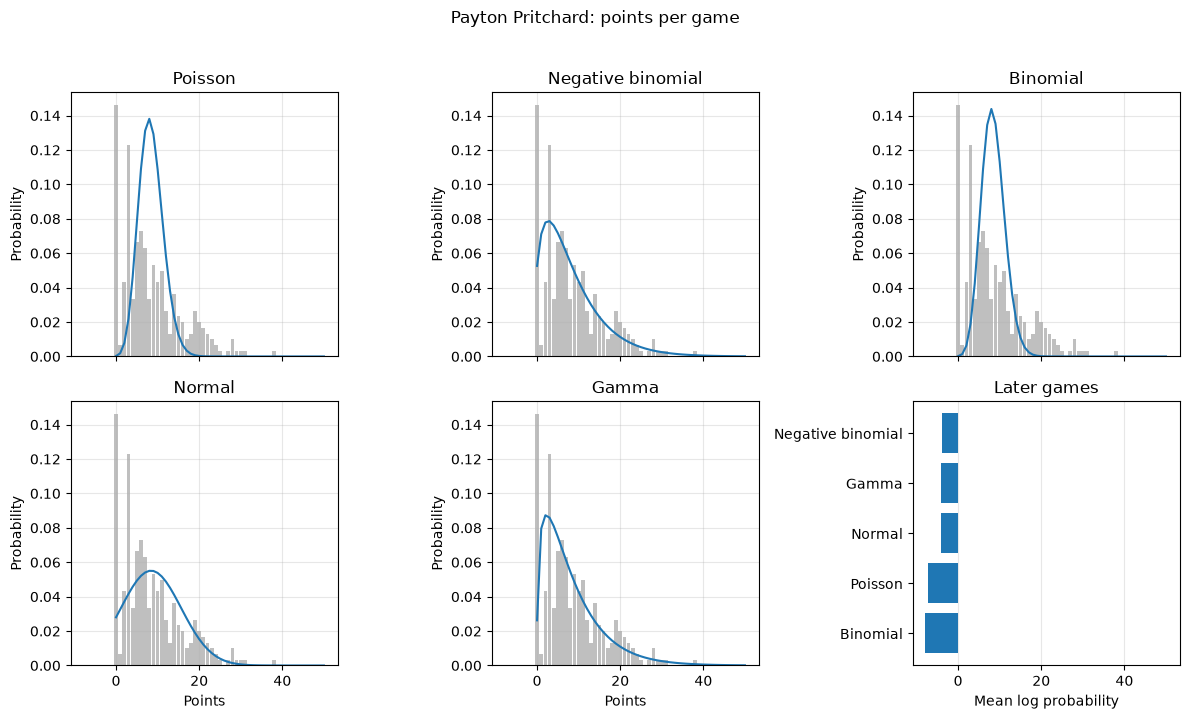

In [ ]:
grid = np.arange(0, int(points.max()) + 8)


def fitted_probability(distribution: str, outcomes: np.ndarray) -> np.ndarray:
    if distribution == "Poisson":
        return stats.poisson.pmf(outcomes, mean)
    if distribution == "Binomial":
        return stats.binom.pmf(outcomes, BINOMIAL_TRIALS, binomial_p)
    if distribution == "Negative binomial":
        if nb_params is None:
            return np.full(outcomes.shape, np.nan)
        return stats.nbinom.pmf(outcomes, nb_n, nb_p)
    if distribution == "Normal":
        return normal.cdf(outcomes + 0.5) - normal.cdf(outcomes - 0.5)
    if distribution == "Gamma":
        return gamma.cdf(outcomes + 0.5) - gamma.cdf(outcomes - 0.5)
    raise ValueError(distribution)


counts_train = np.bincount(train, minlength=int(grid.max()) + 1)
empirical = counts_train / len(train)

figure, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True)
shown = ["Poisson", "Negative binomial", "Binomial", "Normal", "Gamma"]
for axis, distribution in zip(axes.ravel(), shown):
    axis.bar(grid, empirical[grid], color="0.75", width=0.9, label="Train games")
    axis.plot(grid, fitted_probability(distribution, grid), color="C0", label="Fit")
    axis.set_title(distribution)
    axis.set_ylabel("Probability")
    axis.grid(True, alpha=0.3)

score_axis = axes.ravel()[-1]
order = comparison.dropna(subset=["test"]).sort_values("test")
score_axis.barh(order["distribution"], order["test"], color="C0")
score_axis.set_title("Later games")
score_axis.set_xlabel("Mean log probability")
score_axis.grid(True, axis="x", alpha=0.3)

for axis in axes[1, :2]:
    axis.set_xlabel("Points")
figure.suptitle(f"{name}: points per game", y=1.02)
figure.tight_layout()
plt.show()
